# Predict Premier League goalscorers

## Model Training & Evaluation

This notebook documents the process of training and evaluating a machine learning model to predict whether a player will score a goal in a given Premier League gameweek during the 2026/27 season.

The task is framed as a binary classification problem, with the model predicting the likelihood of a player scoring at least one goal in their next fixture.

Model performance is assessed using a range of evaluation metrics, including ROC-AUC and Precision-Recall AUC, alongside visualisations to help interpret and compare results.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### Import data and prepare for training

In [2]:
filepath = "data/csv/dataset_25_6/dataset_25_6_None.csv"
data = pd.read_csv(filepath)

In [4]:
data.columns

Index(['player_name', 'opponent_team', 'was_home', 'gameweek', 'goals_scored',
       'fixture', 'kickoff_time', 'position', 'player_id', 'fdr',
       'goals_last1', 'mins_last1', 'xg_last1', 'threat_last1', 'goals_last3',
       'mins_last3', 'xg_last3', 'threat_last3', 'season_mins', 'season_xg',
       'season_goals', 'season_xg_per90', 'last_ssn_goals', 'last_ssn_xg',
       'last_ssn_mins', 'last_ssn_xgper90', 'last_ssn_glsper90',
       'career_xgper90', 'career_glsper90', 'gc_last1', 'gc_last3',
       'xgc_last1', 'xgc_last3', 'season_xgc', 'season_gc', 'goal_scored'],
      dtype='object')

In [5]:
# Define X and Y sets for training
feature_list = ['position',
               'gameweek',
               'was_home',
               'opponent_team',
               'gc_last3',
               'xgc_last3',
               'season_gc',
               'season_xgc',
               'mins_last1',
               'goals_last1',
               'xg_last1',
               'xg_last3',
                'goals_last3',
                'mins_last3',
                'season_mins',
                'season_xg',
                'season_goals',
                'season_xg_per90',
               'fdr',
               'threat_last1',
               'threat_last3',
               'last_ssn_goals',
               'last_ssn_xg',
               'last_ssn_mins',
               'last_ssn_xgper90',
               'last_ssn_glsper90',
               'career_xgper90',
               'career_glsper90',
               'gc_last1',
               'xgc_last1'
               ]

target_col = data['goal_scored']

### Model training

In [6]:
def walk_forward(df, feature_cols, target_col, min_gw=6, max_gw=30, model=None):
    """Takes as input a dataframe, along with lists of predictor variables and the target variable and trains a walk-forward validation model."""

    if model is None:
        model = RandomForestClassifier(
            n_estimators=300,
            random_state=42
        )

    all_preds = []
    all_true  = []
    all_meta  = []
    
    perm_importances = []
    mdi_importances = []
    
    gameweeks = sorted(df['gameweek'].unique())

    for gw in gameweeks:
        if gw < min_gw or gw > max_gw:
            continue

        train = df[df['gameweek'] < gw]
        test = df[df['gameweek'] == gw]

        X_train = train[feature_cols]
        y_train = train[target_col]
        X_test = test[feature_cols]
        y_test = test[target_col]

        model.fit(X_train, y_train)

        # Calculate feature importance MDI
        mdi_importance = pd.Series(model.feature_importances_,
                                 index=X_train.columns,
                                  name=gw)

        mdi_importances.append(mdi_importance)

        # Calculate feature importance using permutation        
        r = permutation_importance(
                        model,
                        X_test,
                        y_test,
                        random_state=42,
                        scoring='roc_auc'
        )

        p_importance = pd.Series(
            r.importances_mean,
            index=X_train.columns)
    
        perm_importances.append(p_importance)

        # Predict probabilities
        preds = model.predict_proba(X_test)[:, 1]

        all_preds.extend(preds)
        all_true.extend(y_test.values)
        all_meta.append(test[['player_id', 'player_name', 'gameweek', 'opponent_team']].assign(pred=preds, true=y_test.values))

    return all_true, all_preds, pd.concat(all_meta, ignore_index=True), pd.concat(mdi_importances, axis=1), pd.concat(perm_importances, axis=1), model

In [7]:
# Train baseline model
y_true, y_pred, meta, f_importance, permutation_importance, model = walk_forward(df=data, feature_cols=feature_list, target_col='goal_scored')

In [8]:
# Save model weights
joblib.dump(model, "models/fpl_rf_model.joblib")

['models/fpl_rf_model.joblib']

In [9]:
# Check some values
meta[meta['gameweek'] == 18].sort_values('pred', ascending=False).head()

,player_id,player_name,gameweek,opponent_team,pred,true
9722,691,Dominic Calvert-Lewin,18,17,0.686667,1
9461,430,Erling Haaland,18,16,0.616667,0
9078,47,Morgan Rogers,18,7,0.523333,0
9692,661,Hugo Ekitiké,18,20,0.483333,0
9481,450,Matheus Santos Carneiro da Cunha,18,15,0.440000,0


In [10]:
# Save model to file
joblib.dump(model, "model.joblib")

['model.joblib']

### Model evaluation

In [11]:
# Calculate evaluation metrics
roc = roc_auc_score(y_true, y_pred)
prc = average_precision_score(y_true, y_pred)

print(f"ROC AUC value: {roc}\nPRC AUC value: {prc}")

ROC AUC value: 0.8700933229161829
PRC AUC value: 0.16961424490054944


In [12]:
data['goal_scored'].mean()

np.float64(0.030658553803744916)

#### The target variable is extremely imbalanced: only 3.3% of players score in the following gameweek.
A random classifier would therefore achieve a PRC AUC of approximately 0.033.

The baseline model achieved a PRC AUC of 0.132, representing a fourfold improvement over random chance.
The ROC AUC of 0.804 further indicates strong discriminatory power: the model ranks actual scorers ahead of non-scorers 80% of the time.

These results show that the model captures meaningful predictive signal despite the inherent unpredictability of goal scoring and the severe class imbalance.

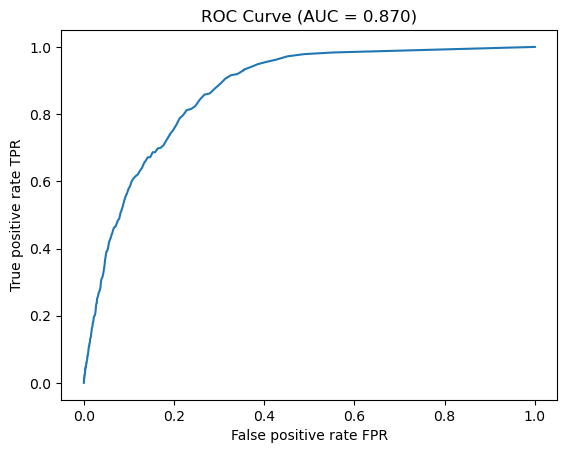

In [13]:
# Plot ROC/PRC AUC

fpr, tpr, thr = roc_curve(y_true, y_pred)
plt.plot(fpr, tpr)
plt.xlabel('False positive rate FPR')
plt.ylabel('True positive rate TPR')
plt.title(f'ROC Curve (AUC = {roc:.3f})')
plt.show()

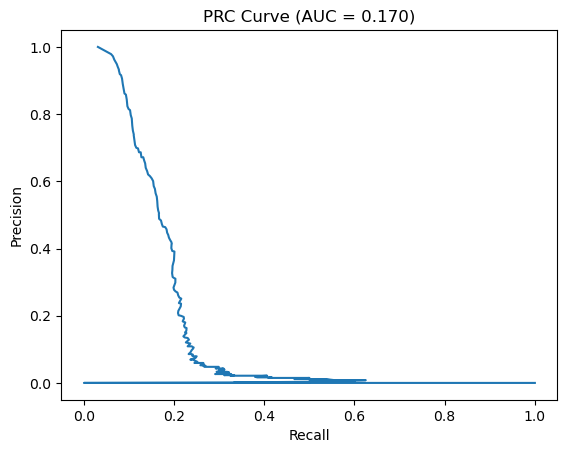

In [14]:
# Plot PRC AUC

precision, recall, _ = precision_recall_curve(y_true, y_pred)
plt.plot(precision, recall)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'PRC Curve (AUC = {prc:.3f})')
plt.show()

#### Next: If I pick the top k players for each gameweek who have the highest P according to my model, how many of them actually scored?

In [15]:
def precision_k(df, k):
    """Takes a dataframe object as input and outputs precision by gameweek of K"""
    precisions = []
    
    for gw, df_gw in df.groupby('gameweek'):
        top_k = df_gw.sort_values('pred', ascending=False).head(k)
        precisions.append(top_k['true'].mean())

    return np.mean(precisions)

In [16]:
k_list = [5, 10, 15, 20]

for k in k_list:
    print(f"Precision at {k}: {precision_k(df=meta, k=k)}")

Precision at 5: 0.272
Precision at 10: 0.244
Precision at 15: 0.23200000000000004
Precision at 20: 0.228


#### Lift = Precision_at_fraction / Base_rate

In [17]:
# Compute lift
base_rate = meta['true'].mean()

for k in [5, 10, 15, 20]:
    prec_k = precision_k(meta, k)
    print(f"Lift @ {k}: {prec_k / base_rate:.2f}x")


Lift @ 5: 8.79x
Lift @ 10: 7.88x
Lift @ 15: 7.49x
Lift @ 20: 7.37x


#### This indicates that our model is many times better than random chance!

In [19]:
def lift_curve(df, fractions):
    """Takes a dataframe and a list of fractions and returns the mean lift at each fraction in a list object"""
    
    base_rate = df['true'].mean()
    
    lifts = []
    
    for fraction in fractions:
        fractional_lifts = []
        
        for gw, df_gw in df.groupby('gameweek'):
            n = len(df_gw)
            k = max(1, int(fraction * n))
            
            top_k = df_gw.sort_values('pred', ascending=False).head(k)
    
            precision = top_k['true'].mean()
            lift = precision / base_rate

            fractional_lifts.append(lift)

        lifts.append(np.mean(fractional_lifts))

    return lifts

In [20]:
fractions = np.linspace(0.01, 1.0, 100)

lifts = lift_curve(meta, fractions)

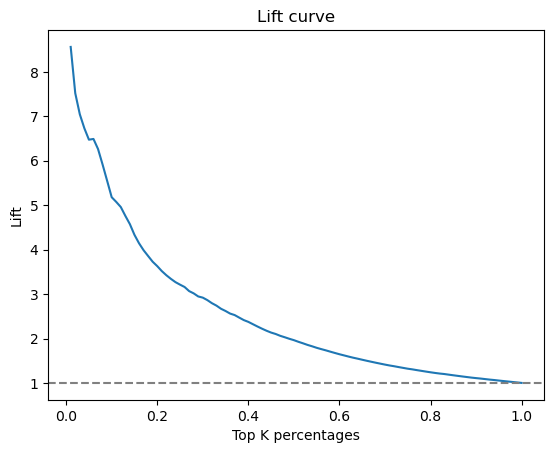

In [21]:
# Plot lift curve

plt.plot(fractions, lifts)
plt.axhline(1, linestyle='--', color='grey')
plt.xlabel("Top K percentages")
plt.ylabel("Lift")
plt.title("Lift curve")

plt.show()

#### Due to the severe class imbalance, ranking-based metrics were used to evaluate model performance.
A lift curve shows that selecting the top 20% of players ranked by predicted scoring probability yields a 3 to 6 fold improvement over random selection.

This demonstrates that the model effectively concentrates goal-scoring events among its highest-ranked predictions, despite the inherent unpredictability of football outcomes.

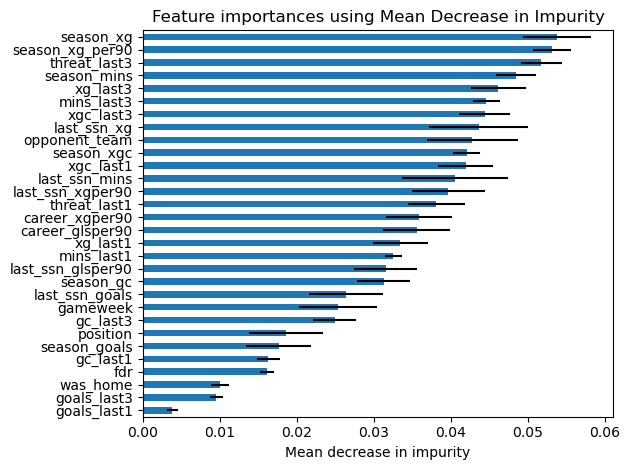

In [22]:
# Feature importance based on mean decrease in impurity

# Calculate mean and standard deviation values
row_mean = f_importance.mean(axis=1)
row_std = f_importance.std(axis=1, ddof=0)

mdi_results = pd.DataFrame({
    'Mean': row_mean,
    'Std': row_std}).sort_values(by='Mean', ascending=True)

# Plot variables
mdi_results['Mean'].plot.barh(xerr=mdi_results['Std'])
plt.title("Feature importances using Mean Decrease in Impurity")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()

#### MDI is biased towards high cardinality features (such as continuous variables) and so we should also check permutation importance too.

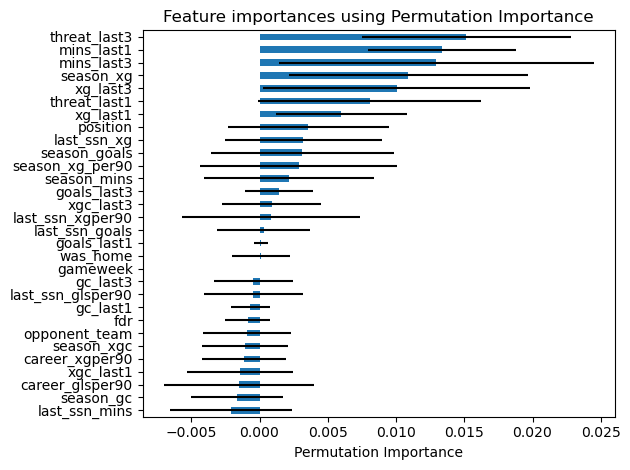

In [23]:
# Change permutation_importance variable known - conflicts with sklearns function

# Permutation importance
pi_mean = permutation_importance.mean(axis=1)
pi_std = permutation_importance.std(axis=1, ddof=0)

perm_results = pd.DataFrame({
    'Mean': pi_mean,
    'Std': pi_std
}).sort_values(by='Mean')

# Plot variables
perm_results['Mean'].plot.barh(xerr=perm_results['Std'])
plt.title("Feature importances using Permutation Importance")
plt.xlabel("Permutation Importance")
plt.tight_layout()

#### Large standard deviation lines show the problem with the method also: 
- Multicollinearity. When one feature is permuted, if it is correlated strongly with another, it doesn't seem to have a big effect on prediction outcomes, when it actually may.

#### Feature importance was assessed using both mean decrease in impurity and permutation importance. 
While permutation importance is more robust to feature scale and cardinality, high correlations among rolling performance statistics resulted in substantial variance in importance estimates. 

This reflects redundancy among related attacking metrics rather than model instability. As the objective of the model is predictive ranking rather than causal inference, correlated features were retained and importance values were interpreted at a group level.

### Sample other models